# 02 · Approfondimenti: confronto modelli, calibrazione, interpretabilità, sopravvivenza

Questo notebook riprende i prossimi passi del notebook `SLA_baseline.ipynb`. La preparazione dei dati sta in `prep.py`, nella stessa cartella.

1. **Etichette "as-of"**: il modello vede solo le etichette note alla data in cui viene addestrato
2. **Confronto modelli** (LightGBM, XGBoost, CatBoost) con validazione temporale a finestre scorrevoli
3. **Modello finale sul test**, anche senza l'ID del richiedente
4. **Calibrazione** delle probabilità e **soglia basata sui costi**
5. **Interpretabilità** con valori SHAP
6. **Richiedenti nuovi**: quanto regge il modello su utenti mai visti?
7. **Tempo di risoluzione con analisi di sopravvivenza**: Kaplan–Meier, XGBoost AFT con censura, regressione quantile
8. Riepilogo e domande per EasyVista

**Requisiti:** `pandas numpy scikit-learn lightgbm xgboost catboost lifelines matplotlib holidays`

### Setup (Colab)
Run these two cells first. The first one writes `prep.py` (shared data preparation) into the working folder, so you do not need to upload it. The second installs the missing libraries and asks you to upload `raw_EV_data_challenge.csv`.

In [ ]:
%%writefile prep.py
"""Shared data preparation for the EasyVista Data Challenge (SLA prediction).

Usage:
    from prep import load_data, CAT_CREATE, NUM_CREATE, ...
    df = load_data("raw_EV_data_challenge.csv")

Changes vs. the first version (see the work guide, section 3):
  * calendar features use Paris local time instead of UTC                     (issue 5)
  * `sla_nominal`: deadline length known at submission, replaces the
    recorded `sla_real_hours`, which looks recomputed during the ticket life (issue 1)
  * `open_recent_30d`: alternative load counter on the last 30 days only (issue 3).
    The rolling CV prefers the original cumulative counter, so it stays in NUM_CREATE
    and the 30-day version is kept in RECENT_LOAD for the ablation
  * `never_closed` flag, to report metrics with and without these tickets    (issue 4)
"""
import numpy as np
import pandas as pd
import holidays

DATE_COLS = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
VALID_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2024-04-01")
REG_TEST_END = pd.Timestamp("2024-08-01")   # margin against censoring for the "plain" regression test
LOCAL_TZ = "Europe/Paris"                   # timestamps are UTC; business hours follow Paris time
LOAD_WINDOW_DAYS = 30                       # look-back window for the load feature

# Features known when the ticket is created (no leakage)
CAT_CREATE = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "SUBMITTED_BY_ID"]
NUM_CREATE = ["sla_nominal", "hour", "dow", "month", "is_weekend", "is_holiday", "off_hours",
              "submitter_missing", "open_tickets_at_submit", "open_same_type_at_submit",
              "arrivals_24h", "arrivals_7d", "submitter_prev_tickets"]

# Kept only for ablations
LEAK_SUSPECT = ["sla_real_hours"]                                  # recorded deadline length (likely leak)
RECENT_LOAD = ["open_recent_30d", "open_recent_30d_same_type"]     # 30-day load counters (no time trend)
CUMULATIVE_LOAD = ["open_tickets_at_submit", "open_same_type_at_submit"]  # in NUM_CREATE; trends with time

# "Oracle" features, known only after the ticket is closed (upper bound, never for production)
CAT_ORACLE = ["LAST_DONE_BY_ID", "STATUS_EN"]
NUM_ORACLE = ["nb_actions"]

MIN_HOURS = 1 / 60  # 1 minute: minimum duration, avoids log(0) in survival models


def load_data(path):
    df = pd.read_csv(path, sep=";", na_values=["NULL"])
    for c in DATE_COLS:
        df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")
    df = df.sort_values("SUBMIT_DATE_UT").reset_index(drop=True)

    # Impossible closing dates (before submission, e.g. 1900-01-01) -> missing
    df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT
    extract = max(df["SUBMIT_DATE_UT"].max(), df["END_DATE_UT"].max())
    df.attrs["extract_date"] = extract

    # Targets, as known at the extraction date
    df["viol"] = viol_as_of(df, extract)
    df["res_hours"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
    df["never_closed"] = df["END_DATE_UT"].isna().astype(int)

    t = df["SUBMIT_DATE_UT"]
    df["split"] = np.where(t < VALID_START, "train", np.where(t < TEST_START, "valid", "test"))
    _add_features(df)
    return df


def viol_as_of(df, cutoff):
    """SLA-violation label as it would have been known at date `cutoff`.
    1   = deadline passed without closure (or closed after the deadline), known if deadline < cutoff
    0   = closed within the deadline, known if closure <= cutoff
    NaN = still unknown at that date (or ticket without SLA)."""
    end, dl = df["END_DATE_UT"], df["MAX_RESOLUTION_DATE_UT"]
    out = pd.Series(np.nan, index=df.index)
    ok0 = dl.notna() & end.notna() & (end <= dl) & (end <= cutoff)
    ok1 = dl.notna() & (dl < cutoff) & (end.isna() | (end > dl))
    out[ok0] = 0.0
    out[ok1] = 1.0
    return out


def duration_as_of(df, cutoff):
    """Duration in hours and event indicator as known at date `cutoff`.
    Tickets not closed by `cutoff` are right-censored at (cutoff - submission)."""
    end = df["END_DATE_UT"]
    observed = end.notna() & (end <= cutoff)
    stop = end.where(observed, cutoff)
    dur = ((stop - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600).clip(lower=MIN_HOURS)
    return dur, observed.astype(int)


def _open_recent(sub_ns, end_ns, window_ns):
    """For each ticket: how many tickets submitted in the previous `window_ns` are still open at its submission.
    Arrays must be sorted by submission time. Uses only information available at submission."""
    first = np.searchsorted(sub_ns, sub_ns - window_ns, side="left")
    before = np.searchsorted(sub_ns, sub_ns, side="left")
    out = np.empty(len(sub_ns), dtype=np.int64)
    for i in range(len(sub_ns)):
        out[i] = np.count_nonzero(end_ns[first[i]:before[i]] >= sub_ns[i])
    return out


def _add_features(df):
    t = df["SUBMIT_DATE_UT"]

    # Recorded deadline length (suspected leakage: kept only for ablations)
    df["sla_real_hours"] = (df["MAX_RESOLUTION_DATE_UT"] - t).dt.total_seconds() / 3600

    # Calendar features in Paris local time (handles daylight saving)
    loc = t.dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    df["hour"] = loc.dt.hour
    df["dow"] = loc.dt.dayofweek
    df["month"] = loc.dt.month
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    fr = holidays.France(years=range(loc.dt.year.min(), loc.dt.year.max() + 1))
    df["is_holiday"] = loc.dt.date.map(lambda d: d in fr).astype(int)
    df["off_hours"] = ((df["hour"] < 8) | (df["hour"] >= 18) | (df["is_weekend"] == 1)
                       | (df["is_holiday"] == 1)).astype(int)
    df["submitter_missing"] = df["SUBMITTED_BY_ID"].isna().astype(int)

    # Nominal deadline length, known at submission: median recorded length for the same
    # SLA_DELAY and hour of the week, estimated on the training period only
    # (a missing SLA_DELAY is treated as its own group: ~130 tickets have a deadline but no SLA_DELAY).
    # The median is robust to the ~9% of deadlines that are extended later on.
    df["hour_of_week"] = df["dow"] * 24 + df["hour"]
    tr = df["split"] == "train"
    by_slot = df[tr].groupby(["SLA_DELAY", "hour_of_week"], dropna=False)["sla_real_hours"].median().rename("_slot")
    by_delay = df[tr].groupby("SLA_DELAY", dropna=False)["sla_real_hours"].median().rename("_delay")
    nom = (df[["SLA_DELAY", "hour_of_week"]]
           .merge(by_slot, left_on=["SLA_DELAY", "hour_of_week"], right_index=True, how="left")
           .merge(by_delay, left_on="SLA_DELAY", right_index=True, how="left"))
    df["sla_nominal"] = nom["_slot"].fillna(nom["_delay"]).values   # fallback: median per SLA_DELAY
    # Diagnostic only (uses the recorded deadline): deadline clearly longer than the nominal one
    df["deadline_extended"] = ((df["sla_real_hours"] > 1.5 * df["sla_nominal"])
                               & (df["sla_real_hours"] - df["sla_nominal"] > 24)).astype(int)

    # System load: only information known at submission
    sub_ns = t.values.astype("datetime64[ns]").astype("int64")
    end_ns = df["END_DATE_UT"].values.astype("datetime64[ns]").astype("int64")
    end_ns = np.where(df["END_DATE_UT"].isna(), np.iinfo("int64").max, end_ns)  # never closed = open forever
    n_before = np.searchsorted(sub_ns, sub_ns, side="left")
    day = np.int64(24 * 3600 * 10**9)

    # Cumulative counters (all tickets ever opened and still open). They grow with time because
    # never-closed tickets pile up and the data starts at zero in Sep 2022, but the rolling CV
    # still prefers them to the 30-day version: keep them, and do not read their SHAP plot as a pure load effect
    df["open_tickets_at_submit"] = n_before - np.searchsorted(np.sort(end_ns), sub_ns, side="left")
    df["open_same_type_at_submit"] = 0
    # 30-day counters: only tickets submitted in the last LOAD_WINDOW_DAYS (the first month of data is a warm-up)
    win = LOAD_WINDOW_DAYS * day
    df["open_recent_30d"] = _open_recent(sub_ns, end_ns, win)
    df["open_recent_30d_same_type"] = 0
    for _, idx in df.groupby("SD_CATALOG_PATH_EN").groups.items():
        s, e = sub_ns[idx], end_ns[idx]
        df.loc[idx, "open_same_type_at_submit"] = np.searchsorted(s, s, side="left") - np.searchsorted(np.sort(e), s, side="left")
        df.loc[idx, "open_recent_30d_same_type"] = _open_recent(s, e, win)

    df["arrivals_24h"] = n_before - np.searchsorted(sub_ns, sub_ns - day, side="left")
    df["arrivals_7d"] = n_before - np.searchsorted(sub_ns, sub_ns - 7 * day, side="left")

    # Submitter history: number of tickets opened before this one (-1 = unknown submitter)
    df["submitter_prev_tickets"] = df.groupby("SUBMITTED_BY_ID").cumcount()
    df.loc[df["SUBMITTED_BY_ID"].isna(), "submitter_prev_tickets"] = -1


def prepare_cats(frame, cats, train_mask, min_count=20):
    """Categoricals as 'category' dtype (LightGBM/XGBoost); rare or unseen levels in train -> '__other__'."""
    X = frame.copy()
    for c in cats:
        s = X[c].astype("string").fillna("__missing__")
        vc = s[train_mask].value_counts()
        keep = set(vc[vc >= min_count].index)
        X[c] = pd.Categorical(s.where(s.isin(keep), "__other__"))
    return X


In [ ]:
# Colab setup: install the libraries that Colab does not preinstall,
# then upload the CSV if it is not in the working folder yet (prep.py is written by the cell above).
!pip install -q catboost lifelines holidays
import os
if not os.path.exists("raw_EV_data_challenge.csv"):
    try:
        from google.colab import files
        print("Please upload raw_EV_data_challenge.csv")
        files.upload()
    except ImportError:
        print("Put raw_EV_data_challenge.csv next to the notebook.")
else:
    print("CSV found.")

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from scipy.stats import norm
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score

from prep import (load_data, viol_as_of, duration_as_of, prepare_cats, CAT_CREATE, NUM_CREATE,
                  LEAK_SUSPECT, RECENT_LOAD, CUMULATIVE_LOAD, TEST_START, REG_TEST_END)

SEED = 42
BLUE, ORANGE, AQUA, GRAY, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 140)

df = load_data("raw_EV_data_challenge.csv")
EXTRACT = df.attrs["extract_date"]
t = df["SUBMIT_DATE_UT"]
print(df.shape, "| estrazione:", EXTRACT)

(64175, 35) | estrazione: 2024-09-16 18:31:03.483000


## 1. Etichette "as-of"

Nel notebook 01 il modello era addestrato con etichette note solo **dopo** la data di cutoff. Esempio: un ticket aperto a dicembre 2023 e chiuso a febbraio 2024 era usato come esempio "chiuso" già nel training di gennaio 2024.

Qui ogni modello addestrato alla data *c* vede l'etichetta di violazione solo se a quella data era già nota:
- **violato** se la scadenza era già passata e il ticket non era chiuso (o è stato chiuso in ritardo)
- **rispettato** se il ticket era già chiuso entro la scadenza
- altrimenti l'etichetta è ignota e il ticket esce dal training

Lo stesso vale per il tempo di risoluzione: un ticket ancora aperto alla data *c* è **censurato**, cioè sappiamo solo che dura *almeno* fino a *c*.

In [2]:
for c in [pd.Timestamp("2023-07-01"), pd.Timestamp("2024-01-01"), TEST_START]:
    m = (t < c) & df["MAX_RESOLUTION_DATE_UT"].notna()
    v = viol_as_of(df, c)[m]
    _, ev = duration_as_of(df, c)
    print(f"cutoff {c.date()}: etichette note {v.notna().mean():.1%} | tasso violazione noto {v.mean():.3f} "
          f"| durate censurate {1 - ev[t < c].mean():.1%}")

cutoff 2023-07-01: etichette note 98.9% | tasso violazione noto 0.255 | durate censurate 10.3%
cutoff 2024-01-01: etichette note 99.5% | tasso violazione noto 0.258 | durate censurate 6.8%
cutoff 2024-04-01: etichette note 99.3% | tasso violazione noto 0.254 | durate censurate 6.0%


### Data-quality diagnostics
(a) Recorded deadlines much longer than the nominal one go with much longer tickets: the deadline is probably moved during the ticket's life. (b) The cumulative open-ticket counter trends with time; the 30-day one does not.

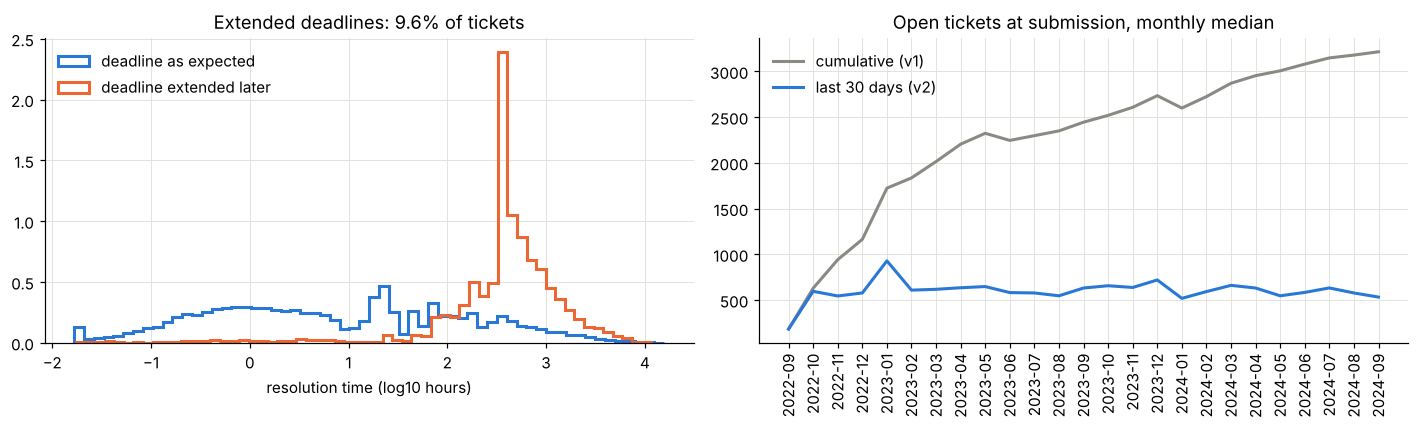

In [3]:
# Two figures that justify the fixes: (a) recorded deadlines longer than the nominal one
# go with much longer tickets; (b) the old load counter trends with time, the new one does not.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d = df[df["viol"].notna()]
for flag, col, lab in [(0, BLUE, "deadline as expected"), (1, ORANGE, "deadline extended later")]:
    h = np.log10(d.loc[d.deadline_extended == flag, "res_hours"].dropna().clip(lower=1 / 60))
    axes[0].hist(h, bins=60, density=True, histtype="step", lw=2, color=col, label=lab)
axes[0].set_xlabel("resolution time (log10 hours)"); axes[0].legend(frameon=False)
axes[0].set_title(f"Extended deadlines: {d.deadline_extended.mean():.1%} of tickets")
q = df.groupby(t.dt.to_period("M"))[["open_tickets_at_submit", "open_recent_30d"]].median()
axes[1].plot(q.index.astype(str), q["open_tickets_at_submit"], color=GRAY, lw=2, label="cumulative (v1)")
axes[1].plot(q.index.astype(str), q["open_recent_30d"], color=BLUE, lw=2, label="last 30 days (v2)")
axes[1].set_title("Open tickets at submission, monthly median"); axes[1].legend(frameon=False)
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()


## 2. Confronto modelli con validazione temporale scorrevole

Quattro fold, tutti **prima** del test (che parte ad aprile 2024):

| fold | training (etichette note a inizio validazione) | early stopping | validazione |
|---|---|---|---|
| 1 | fino a ~feb 2023 | ultime 8 settimane prima di apr 2023 | apr–giu 2023 |
| 2 | fino a ~mag 2023 | ultime 8 settimane | lug–set 2023 |
| 3 | fino a ~ago 2023 | ultime 8 settimane | ott–dic 2023 |
| 4 | fino a ~nov 2023 | ultime 8 settimane | gen–mar 2024 |

Lo stesso schema, con inizio al 1° aprile 2024, produce il modello finale (sezione 3).

In [4]:
ES_WEEKS = pd.Timedelta(weeks=8)
FEATS = CAT_CREATE + NUM_CREATE
has_sla = df["MAX_RESOLUTION_DATE_UT"].notna()

def split_masks(start, months=3):
    end = start + pd.DateOffset(months=months)
    lab = viol_as_of(df, start)
    tr = has_sla & (t < start - ES_WEEKS) & lab.notna()
    es = has_sla & (t >= start - ES_WEEKS) & (t < start) & lab.notna()
    ev = has_sla & (t >= start) & (t < end) & df["viol"].notna()
    y = lab.where(~ev, df["viol"])  # etichette as-of per train/ES, etichette finali per la valutazione
    return tr, es, ev, y

def fit_predict(kind, cats, nums, tr, es, y, params=None, pred_masks=()):
    """Addestra su `tr` con early stopping su `es`; restituisce le probabilità su `es` e su ogni maschera richiesta."""
    X = prepare_cats(df[cats + nums], cats, tr)
    ytr, yes = y[tr].astype(int), y[es].astype(int)
    if kind == "lightgbm":
        p = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_child_samples=40,
                 feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED)
        p.update(params or {})
        m = lgb.train(p, lgb.Dataset(X[tr], ytr, categorical_feature=cats), 4000,
                      valid_sets=[lgb.Dataset(X[es], yes, categorical_feature=cats)],
                      callbacks=[lgb.early_stopping(150, verbose=False)])
        pred = lambda mask: m.predict(X[mask], num_iteration=m.best_iteration)
    elif kind == "xgboost":
        p = dict(objective="binary:logistic", eval_metric="logloss", eta=0.03, max_depth=7, min_child_weight=5,
                 subsample=0.8, colsample_bytree=0.8, tree_method="hist", max_cat_to_onehot=1, seed=SEED)
        p.update(params or {})
        dtr = xgb.DMatrix(X[tr], ytr, enable_categorical=True)
        des = xgb.DMatrix(X[es], yes, enable_categorical=True)
        m = xgb.train(p, dtr, 4000, evals=[(des, "es")], early_stopping_rounds=150, verbose_eval=False)
        pred = lambda mask: m.predict(xgb.DMatrix(X[mask], enable_categorical=True),
                                      iteration_range=(0, m.best_iteration + 1))
    elif kind == "catboost":
        Xc = X.copy()
        for c in cats:
            Xc[c] = Xc[c].astype(str)
        m = CatBoostClassifier(iterations=3000, learning_rate=0.06, depth=6, eval_metric="Logloss",
                               od_type="Iter", od_wait=150, random_seed=SEED, verbose=0, thread_count=-1,
                               **(params or {}))
        m.fit(Xc[tr], ytr, cat_features=cats, eval_set=(Xc[es], yes), use_best_model=True)
        pred = lambda mask: m.predict_proba(Xc[mask])[:, 1]
    return m, X, [pred(es)] + [pred(pm) for pm in pred_masks]

In [5]:
FOLD_STARTS = pd.to_datetime(["2023-04-01", "2023-07-01", "2023-10-01", "2024-01-01"])
CANDIDATES = {
    "LightGBM": ("lightgbm", None),
    "LightGBM (foglie 15, min 100)": ("lightgbm", dict(num_leaves=15, min_child_samples=100)),
    "XGBoost": ("xgboost", None),
    "CatBoost": ("catboost", None),
}
cv_rows = []
for k, start in enumerate(FOLD_STARTS, 1):
    tr, es, ev, y = split_masks(start)
    for name, (kind, params) in CANDIDATES.items():
        _, _, (_, p) = fit_predict(kind, CAT_CREATE, NUM_CREATE, tr, es, y, params, pred_masks=[ev])
        cv_rows.append(dict(fold=k, model=name, n_val=int(ev.sum()), viol_rate=y[ev].mean(),
                            ROC_AUC=roc_auc_score(y[ev], p), PR_AUC=average_precision_score(y[ev], p)))
cv = pd.DataFrame(cv_rows)
summary = cv.groupby("model")[["ROC_AUC", "PR_AUC"]].agg(["mean", "std"]).round(3)
summary["PR_lift"] = (cv.assign(l=cv.PR_AUC / cv.viol_rate).groupby("model")["l"].mean()).round(2)
summary.sort_values(("PR_AUC", "mean"), ascending=False)

ROC_AUC        PR_AUC        PR_lift
                                 mean    std   mean    std        
model                                                             
LightGBM (foglie 15, min 100)   0.657  0.027  0.363  0.027    1.48
LightGBM                        0.651  0.028  0.352  0.022    1.44
XGBoost                         0.637  0.045  0.349  0.013    1.43
CatBoost                        0.600  0.083  0.318  0.016    1.31

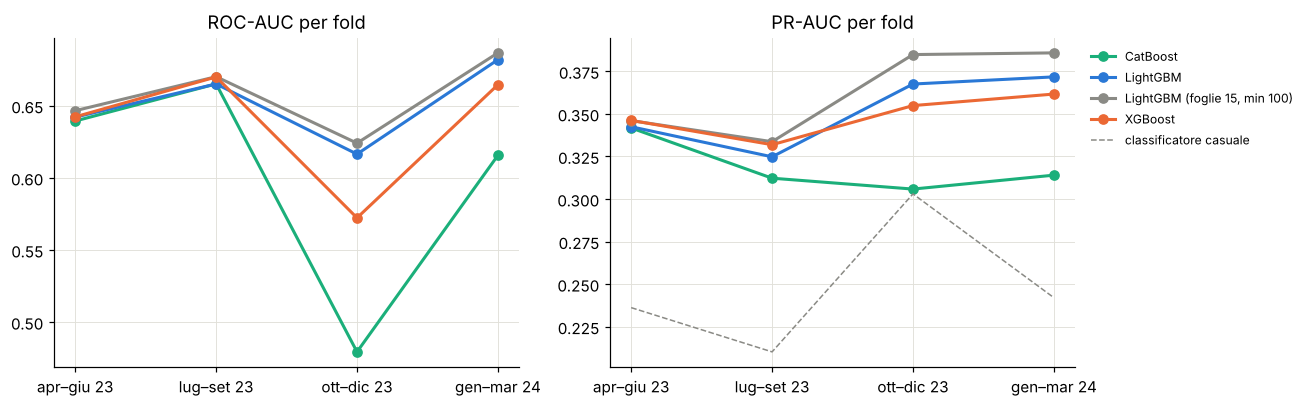

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
colors = {"LightGBM": BLUE, "LightGBM (foglie 15, min 100)": GRAY, "XGBoost": ORANGE, "CatBoost": AQUA}
for name, g in cv.groupby("model"):
    for ax, met in zip(axes, ["ROC_AUC", "PR_AUC"]):
        ax.plot(g.fold, g[met], marker="o", ms=6, lw=2, color=colors[name], label=name)
for ax, met in zip(axes, ["ROC-AUC", "PR-AUC"]):
    ax.set_title(f"{met} per fold"); ax.set_xticks(range(1, 5))
    ax.set_xticklabels(["apr–giu 23", "lug–set 23", "ott–dic 23", "gen–mar 24"])
axes[1].plot(cv[cv.model == "LightGBM"].fold, cv[cv.model == "LightGBM"].viol_rate, ls="--", color=GRAY, lw=1,
             label="classificatore casuale")
axes[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## 3. Modello finale e test (apr–set 2024)

Riaddestriamo con lo stesso schema e inizio al 1° aprile 2024: training fino a inizio febbraio 2024, le ultime 8 settimane servono per early stopping, calibrazione e soglia. Confrontiamo anche un LightGBM **senza** `SUBMITTED_BY_ID`.

In [7]:
# The final configuration is chosen from the rolling cross-validation, NEVER from the
# test set (issue 2). The test table below is shown for information only: BEST is
# fixed before looking at it.
BEST = summary[("PR_AUC", "mean")].idxmax()
print("configuration chosen by CV:", BEST)

tr, es, te, y = split_masks(TEST_START, months=6)
y_es, y_te = y[es].astype(int).values, y[te].astype(int).values
print(f"train {tr.sum()} | ES/calibration {es.sum()} | test {te.sum()} | test violation rate {y_te.mean():.3f}")

final, test_rows = {}, []
for name in dict.fromkeys([BEST, "LightGBM", "XGBoost", "CatBoost"]):   # BEST first, no duplicates
    kind, params = CANDIDATES[name]
    m, X, (p_es, p_te) = fit_predict(kind, CAT_CREATE, NUM_CREATE, tr, es, y, params, pred_masks=[te])
    final[name] = dict(model=m, X=X, p_es=p_es, p_te=p_te)

# Same model as BEST but without the submitter ID: does it work for unseen users?
cats_nosub = [c for c in CAT_CREATE if c != "SUBMITTED_BY_ID"]
nums_nosub = [c for c in NUM_CREATE if c not in ("submitter_prev_tickets", "submitter_missing")]
kind, params = CANDIDATES[BEST]
m, X, (p_es, p_te) = fit_predict(kind, cats_nosub, nums_nosub, tr, es, y, params, pred_masks=[te])
final["LightGBM senza richiedente"] = dict(model=m, X=X, p_es=p_es, p_te=p_te)  # key kept for the later cells

for name, r in final.items():
    test_rows.append(dict(model=name, chosen_by_CV=(name == BEST),
                          ROC_AUC=roc_auc_score(y_te, r["p_te"]),
                          PR_AUC=average_precision_score(y_te, r["p_te"]),
                          Brier=brier_score_loss(y_te, r["p_te"])))
test_res = pd.DataFrame(test_rows).set_index("model").round(3)
test_res


configuration chosen by CV: LightGBM (foglie 15, min 100)
train 38771 | ES/calibration 5505 | test 15330 | test violation rate 0.265


,chosen_by_CV,ROC_AUC,PR_AUC,Brier
model,,,,
"LightGBM (foglie 15, min 100)",True,0.703,0.461,0.175
LightGBM,False,0.715,0.517,0.170
XGBoost,False,0.705,0.464,0.175
CatBoost,False,0.701,0.469,0.175
LightGBM senza richiedente,False,0.695,0.500,0.173


## 4. Calibrazione e soglia basata sui costi

**Calibrazione:** se il modello dice 30%, circa 30 ticket su 100 devono davvero violare lo SLA. Usiamo una regressione isotonica stimata sul set di early stopping.

**Soglia:** l'F1 tratta allo stesso modo falsi positivi e falsi negativi. In pratica una violazione non prevista (FN) costa molto più di un falso allarme (FP). **Ipotesi di lavoro: FN = 5, FP = 1**, da concordare con EasyVista. Con probabilità ben calibrate la soglia ottimale teorica è

$$p^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{1+5} \approx 0.167$$

cioè conviene segnalare il ticket appena il rischio supera circa 1 su 6.

In [8]:
p_es_raw, p_te_raw = final[BEST]["p_es"], final[BEST]["p_te"]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_es_raw, y_es)
p_te_cal = iso.predict(p_te_raw)
print(f"Brier test: grezzo {brier_score_loss(y_te, p_te_raw):.4f} | calibrato {brier_score_loss(y_te, p_te_cal):.4f}")

def reliability(p, y, bins=10):
    q = pd.qcut(p, bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y}).groupby(q, observed=True).mean()
    return g.p.values, g.y.values

C_FN, C_FP = 5, 1
thr = np.linspace(0.01, 0.9, 90)
def cost_per_1000(p, y, th):
    yhat = p >= th
    return 1000 * (C_FN * ((~yhat) & (y == 1)).sum() + C_FP * (yhat & (y == 0)).sum()) / len(y)

cost_es = np.array([cost_per_1000(iso.predict(p_es_raw), y_es, th) for th in thr])
th_cost = thr[cost_es.argmin()]
f1_es = np.array([f1_score(y_es, iso.predict(p_es_raw) >= th) for th in thr])
th_f1 = thr[f1_es.argmax()]
rows = []
for label, th in [("soglia 0.5", 0.5), (f"max F1 (su ES) = {th_f1:.2f}", th_f1),
                  (f"min costo (su ES) = {th_cost:.2f}", th_cost), ("teorica 1/6", 1 / 6)]:
    yhat = p_te_cal >= th
    rows.append(dict(regola=label, costo_per_1000=cost_per_1000(p_te_cal, y_te, th),
                     recall=(yhat & (y_te == 1)).sum() / (y_te == 1).sum(),
                     precision=(yhat & (y_te == 1)).sum() / max(yhat.sum(), 1), ticket_segnalati=yhat.mean()))
rows.append(dict(regola="nessun allarme", costo_per_1000=cost_per_1000(p_te_cal, y_te, 2.0), recall=0,
                 precision=np.nan, ticket_segnalati=0))
rows.append(dict(regola="allarme su tutti", costo_per_1000=cost_per_1000(p_te_cal, y_te, -1), recall=1,
                 precision=y_te.mean(), ticket_segnalati=1))
pd.DataFrame(rows).set_index("regola").round(3)

Brier test: grezzo 0.1753 | calibrato 0.1757


,costo_per_1000,recall,precision,ticket_segnalati
regola,,,,
soglia 0.5,1111.416,0.189,0.577,0.087
max F1 (su ES) = 0.18,652.642,0.783,0.363,0.573
min costo (su ES) = 0.16,630.007,0.855,0.341,0.664
teorica 1/6,630.007,0.855,0.341,0.664
nessun allarme,1325.506,0.000,NaN,0.000
allarme su tutti,734.899,1.000,0.265,1.000


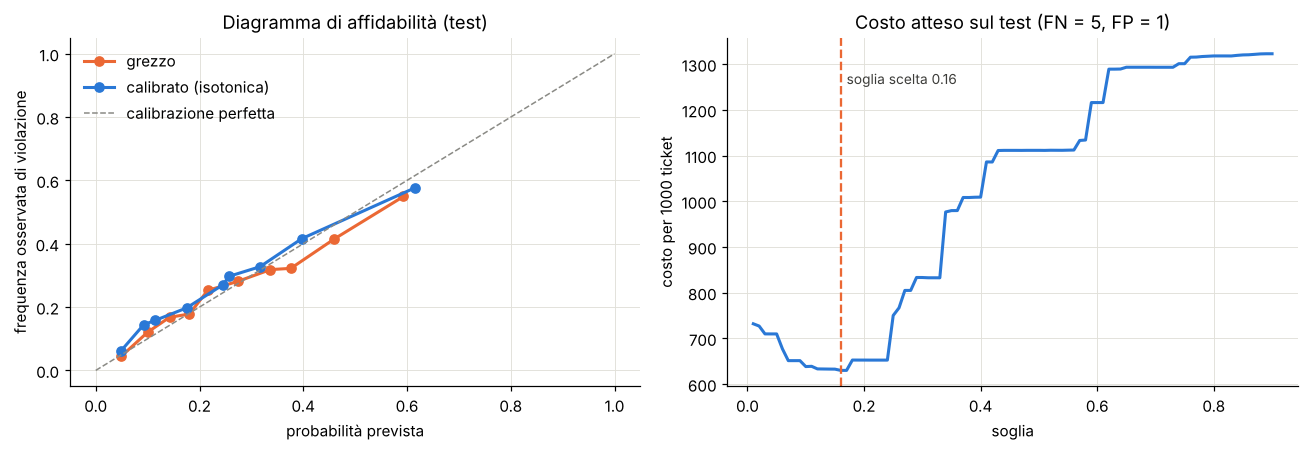

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for p, lab, col in [(p_te_raw, "grezzo", ORANGE), (p_te_cal, "calibrato (isotonica)", BLUE)]:
    x, yy = reliability(p, y_te)
    axes[0].plot(x, yy, marker="o", ms=6, lw=2, color=col, label=lab)
axes[0].plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="calibrazione perfetta")
axes[0].set_xlabel("probabilità prevista"); axes[0].set_ylabel("frequenza osservata di violazione")
axes[0].set_title("Diagramma di affidabilità (test)"); axes[0].legend(frameon=False)
cost_te = [cost_per_1000(p_te_cal, y_te, th) for th in thr]
axes[1].plot(thr, cost_te, color=BLUE, lw=2)
axes[1].axvline(th_cost, color=ORANGE, lw=1.5, ls="--")
axes[1].text(th_cost + 0.01, max(cost_te) * 0.95, f"soglia scelta {th_cost:.2f}", color="#3d3d3a", fontsize=9)
axes[1].set_xlabel("soglia"); axes[1].set_ylabel("costo per 1000 ticket")
axes[1].set_title(f"Costo atteso sul test (FN = {C_FN}, FP = {C_FP})")
plt.tight_layout(); plt.show()

## 3b. Feature ablation
Same model and folds, different feature sets: recorded vs nominal deadline, cumulative vs 30-day load.

In [10]:
# How much of the score comes from the suspicious features? Same model (BEST), same CV
# folds and same test, only the feature set changes (issues 1 and 3).
# The final feature set is the one with the best CV score among those WITHOUT the leak:
# in our run "nominal deadline + cumulative load" (CV ROC 0.654 vs 0.642 for the 30-day load).
from prep import LEAK_SUSPECT, RECENT_LOAD, CUMULATIVE_LOAD
base_nums = [c for c in NUM_CREATE if c not in ["sla_nominal"] + CUMULATIVE_LOAD]
FEATURE_SETS = {
    "v1: recorded deadline + cumulative load (leak)": base_nums + LEAK_SUSPECT + CUMULATIVE_LOAD,
    "nominal deadline + cumulative load (final)": NUM_CREATE,
    "nominal deadline + 30-day load": base_nums + ["sla_nominal"] + RECENT_LOAD,
    "no deadline feature + cumulative load": base_nums + CUMULATIVE_LOAD,
}
kind, params = CANDIDATES[BEST]
abl_rows = []
for set_name, nums in FEATURE_SETS.items():
    row = dict(features=set_name)
    cv_scores = []
    for start in FOLD_STARTS:                                   # rolling CV, before the test period
        tr_, es_, ev_, y_ = split_masks(start)
        _, _, (_, p) = fit_predict(kind, CAT_CREATE, nums, tr_, es_, y_, params, pred_masks=[ev_])
        cv_scores.append((roc_auc_score(y_[ev_], p), average_precision_score(y_[ev_], p)))
    row["CV_ROC_AUC"], row["CV_PR_AUC"] = np.mean(cv_scores, axis=0)
    tr_, es_, ev_, y_ = split_masks(TEST_START, months=6)       # test period
    _, _, (_, p) = fit_predict(kind, CAT_CREATE, nums, tr_, es_, y_, params, pred_masks=[ev_])
    row["test_ROC_AUC"], row["test_PR_AUC"] = roc_auc_score(y_[ev_], p), average_precision_score(y_[ev_], p)
    abl_rows.append(row)
pd.DataFrame(abl_rows).set_index("features").round(3)


,CV_ROC_AUC,CV_PR_AUC,test_ROC_AUC,test_PR_AUC
features,,,,
v1: recorded deadline + cumulative load (leak),0.675,0.401,0.730,0.532
nominal deadline + cumulative load (final),0.657,0.363,0.703,0.461
nominal deadline + 30-day load,0.642,0.352,0.688,0.414
no deadline feature + cumulative load,0.658,0.364,0.700,0.469


### Sensitivity to never-closed tickets

In [11]:
# Open tickets past their deadline are labelled "violated". They are 14% of the test
# violations but only ~3% in train, so we report the metrics with and without them.
nc = df.loc[te, "never_closed"].values == 1
rows = []
for label, mk in [("all test tickets", np.ones_like(nc)), ("closed tickets only", ~nc)]:
    p = final[BEST]["p_te"][mk]
    rows.append(dict(subset=label, n=mk.sum(), viol_rate=y_te[mk].mean(),
                     ROC_AUC=roc_auc_score(y_te[mk], p), PR_AUC=average_precision_score(y_te[mk], p)))
print(f"never-closed tickets in test: {nc.sum()} ({y_te[nc].sum()} of {y_te.sum()} violations)")
pd.DataFrame(rows).set_index("subset").round(3)


never-closed tickets in test: 575 (575 of 4064 violations)


,n,viol_rate,ROC_AUC,PR_AUC
subset,,,,
all test tickets,15330,0.265,0.703,0.461
closed tickets only,14755,0.236,0.714,0.432


## 5. Interpretabilità: valori SHAP

Per ogni ticket il valore SHAP dice quanto ogni feature sposta la previsione, in log-odds, rispetto alla media. LightGBM li calcola direttamente con `pred_contrib=True`, senza il pacchetto `shap`.

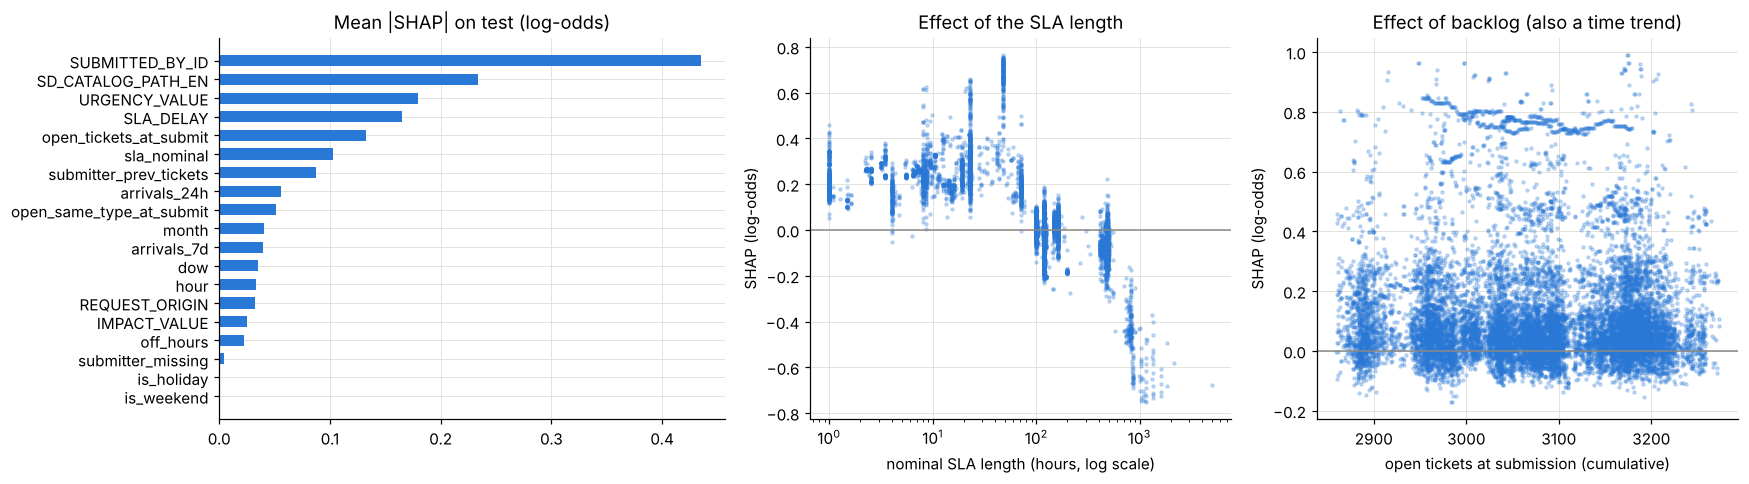

In [12]:
# Same plots, with the nominal deadline. The load plot uses the cumulative counter, which
# also trends with time (issue 3): describe it as "backlog / period effect", not pure load.
m_lgb, X_lgb = final["LightGBM"]["model"], final["LightGBM"]["X"]
contrib = m_lgb.predict(X_lgb[te], num_iteration=m_lgb.best_iteration, pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=m_lgb.feature_name(), index=X_lgb[te].index)
mean_abs = shap_df.abs().mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axes[0].barh(mean_abs.index, mean_abs.values, color=BLUE, height=0.6)
axes[0].set_title("Mean |SHAP| on test (log-odds)")
axes[1].scatter(df.loc[te, "sla_nominal"].clip(lower=0.5), shap_df["sla_nominal"], s=4, alpha=0.25, color=BLUE)
axes[1].set_xscale("log"); axes[1].axhline(0, color=GRAY, lw=1)
axes[1].set_xlabel("nominal SLA length (hours, log scale)"); axes[1].set_title("Effect of the SLA length")
axes[2].scatter(df.loc[te, "open_tickets_at_submit"], shap_df["open_tickets_at_submit"], s=4, alpha=0.25, color=BLUE)
axes[2].axhline(0, color=GRAY, lw=1)
axes[2].set_xlabel("open tickets at submission (cumulative)"); axes[2].set_title("Effect of backlog (also a time trend)")
for ax in axes[1:]:
    ax.set_ylabel("SHAP (log-odds)")
plt.tight_layout(); plt.show()


In [13]:
# Effetto medio per categoria (tipo di ticket, urgenza, canale)
for c in ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "REQUEST_ORIGIN"]:
    print(shap_df[c].groupby(df.loc[te, c]).agg(["mean", "size"]).round(3).sort_values("mean").to_string(), "\n")

                     mean  size
SD_CATALOG_PATH_EN             
Service Request    -0.334  6255
Change              0.001     1
Incidents           0.164  9073 

                mean  size
URGENCY_VALUE             
5             -0.254  6297
4             -0.069    35
1             -0.020   543
2              0.069  1632
3              0.147  6823 

                            mean   size
REQUEST_ORIGIN                         
Email                     -0.096   2218
Webservice - EvO Platform -0.075    226
Front Office               0.013  11927
Webservice - ES Platform   0.062    211
Phone                      0.114    746
Shopping Cart              0.162      2 



## 6. Richiedenti nuovi

`SUBMITTED_BY_ID` è la feature più importante. Il modello ha un livello proprio solo per i richiedenti con almeno 20 ticket nel training; tutti gli altri finiscono in `__other__` o `__missing__`. Confrontiamo i due gruppi nel test.

In [14]:
sub_level = final["LightGBM"]["X"].loc[te, "SUBMITTED_BY_ID"].astype(str)
group = np.where(sub_level == "__missing__", "senza richiedente (es. email)",
                 np.where(sub_level == "__other__", "nuovo o raro (<20 ticket)", "noto (≥20 ticket)"))
rows = []
for g in pd.unique(group):
    mk = group == g
    r = dict(gruppo=g, n=mk.sum(), viol_rate=y_te[mk].mean())
    for name in ["LightGBM", "LightGBM senza richiedente"]:
        r[f"PR_AUC {name}"] = average_precision_score(y_te[mk], final[name]["p_te"][mk])
        r[f"ROC_AUC {name}"] = roc_auc_score(y_te[mk], final[name]["p_te"][mk])
    rows.append(r)
pd.DataFrame(rows).set_index("gruppo").round(3)

,n,viol_rate,PR_AUC LightGBM,ROC_AUC LightGBM,PR_AUC LightGBM senza richiedente,ROC_AUC LightGBM senza richiedente
gruppo,,,,,,
senza richiedente (es. email),2193,0.389,0.858,0.860,0.832,0.843
nuovo o raro (<20 ticket),5125,0.273,0.342,0.596,0.351,0.600
noto (≥20 ticket),8012,0.226,0.428,0.725,0.390,0.689


## 7. Tempo di risoluzione con analisi di sopravvivenza

### 7a. Curve di Kaplan–Meier
La curva dà la probabilità che un ticket sia **ancora aperto** dopo *x* ore, tenendo conto correttamente dei ticket non ancora chiusi (censurati).

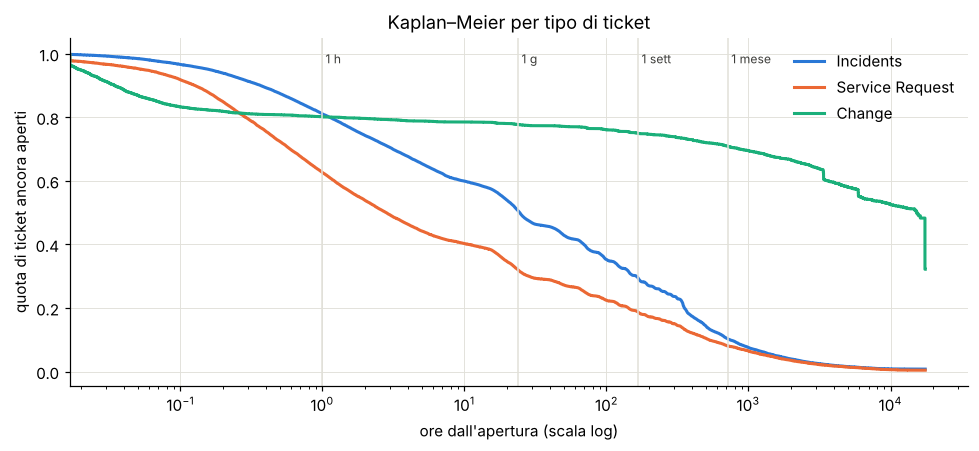

,mediana (ore),aperti dopo 1 h,aperti dopo 1 g,aperti dopo 1 sett,aperti dopo 1 mese
Incidents,24.532,0.811,0.505,0.292,0.102
Service Request,2.814,0.626,0.319,0.186,0.080
Change,15411.798,0.802,0.777,0.749,0.708


In [15]:
dur_all, ev_all = duration_as_of(df, EXTRACT)
fig, ax = plt.subplots(figsize=(9, 4.2))
kmf = KaplanMeierFitter()
km_tab = {}
for cat, col in [("Incidents", BLUE), ("Service Request", ORANGE), ("Change", AQUA)]:
    mk = df["SD_CATALOG_PATH_EN"] == cat
    kmf.fit(dur_all[mk], ev_all[mk], label=cat)
    ax.step(kmf.survival_function_.index, kmf.survival_function_[cat], where="post", color=col, lw=2, label=cat)
    km_tab[cat] = {"mediana (ore)": kmf.median_survival_time_,
                   **{f"aperti dopo {k}": float(kmf.predict(v))
                      for k, v in {"1 h": 1, "1 g": 24, "1 sett": 168, "1 mese": 720}.items()}}
ax.set_xscale("log"); ax.set_xlim(1 / 60, None)
for h, lab in [(1, "1 h"), (24, "1 g"), (168, "1 sett"), (720, "1 mese")]:
    ax.axvline(h, color=GRID, lw=1); ax.text(h * 1.05, 0.97, lab, fontsize=8, color="#3d3d3a")
ax.set_xlabel("ore dall'apertura (scala log)"); ax.set_ylabel("quota di ticket ancora aperti")
ax.set_title("Kaplan–Meier per tipo di ticket"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
pd.DataFrame(km_tab).T.round(3)

### 7b. Due modelli per la durata

Entrambi addestrati con le informazioni note al 1° aprile 2024 e lo stesso schema train / early stopping:
- **LightGBM quantile "ingenuo"** (10°, 50°, 90° percentile): usa solo i ticket già chiusi e scarta i censurati, quindi è distorto verso i ticket brevi (quelli lunghi sono spesso ancora aperti). Il quantile 50% coincide con la regressione L1 del notebook 01, perché minimizzare l'errore assoluto equivale a stimare la mediana.
- **XGBoost AFT** (*accelerated failure time*): modella log(durata) = μ(x) + σ·Z con Z normale, e usa i ticket censurati come "durata ≥ valore osservato".

Valutazione sul test (apr–set 2024, durate note all'estrazione):
- **C-index**: probabilità che, presi due ticket, il modello ordini correttamente chi si chiude prima. Usa anche i censurati; 0.5 = caso.
- **MAE log**: errore medio su log(ore), solo per i ticket chiusi e aperti prima di agosto 2024. MAE log = 1 vuol dire sbagliare in media di un fattore e ≈ 2.7. Qui si usa log(ore), non log(1+ore) come nel notebook 01: i due valori non sono confrontabili, perché log(1+ore) comprime i ticket brevissimi.
- **Copertura** dell'intervallo all'80%: deve essere vicina all'80%.

In [16]:
dur_c, ev_c = duration_as_of(df, TEST_START)
rtr = (t < TEST_START - ES_WEEKS)
res = (t >= TEST_START - ES_WEEKS) & (t < TEST_START)
rte = (t >= TEST_START)
obs_te = rte & (ev_all == 1) & (t < REG_TEST_END)
Xr = prepare_cats(df[FEATS], CAT_CREATE, rtr)
logd_c, logd_all = np.log(dur_c), np.log(dur_all)
print(f"training: {rtr.sum()} ticket, di cui censurati {1 - ev_c[rtr].mean():.1%}")

LGB_REG = dict(learning_rate=0.03, num_leaves=63, min_child_samples=40, feature_fraction=0.8,
               bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED)
def lgb_reg(objective, alpha=None):
    p = dict(LGB_REG, objective=objective, **({"alpha": alpha} if alpha else {}))
    a, b = rtr & (ev_c == 1), res & (ev_c == 1)  # solo ticket chiusi ("ingenuo")
    m = lgb.train(p, lgb.Dataset(Xr[a], logd_c[a], categorical_feature=CAT_CREATE), 4000,
                  valid_sets=[lgb.Dataset(Xr[b], logd_c[b], categorical_feature=CAT_CREATE)],
                  callbacks=[lgb.early_stopping(150, verbose=False)])
    return m.predict(Xr[rte], num_iteration=m.best_iteration)

q10, q50, q90 = (lgb_reg("quantile", a) for a in (0.1, 0.5, 0.9))

def aft_dmatrix(mask):
    d = xgb.DMatrix(Xr[mask], enable_categorical=True)
    lo = dur_c[mask].values
    hi = np.where(ev_c[mask].values == 1, lo, np.inf)
    d.set_float_info("label_lower_bound", lo); d.set_float_info("label_upper_bound", hi)
    return d
dtr_aft, des_aft = aft_dmatrix(rtr), aft_dmatrix(res)
best = None
for sigma in [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]:
    p = dict(objective="survival:aft", eval_metric="aft-nloglik", aft_loss_distribution="normal",
             aft_loss_distribution_scale=sigma, eta=0.03, max_depth=7, min_child_weight=5, subsample=0.8,
             colsample_bytree=0.8, tree_method="hist", max_cat_to_onehot=1, seed=SEED)
    m = xgb.train(p, dtr_aft, 4000, evals=[(des_aft, "es")], early_stopping_rounds=150, verbose_eval=False)
    print(f"sigma = {sigma}: nloglik ES = {m.best_score:.4f}")
    if best is None or m.best_score < best[1]:
        best = (sigma, m.best_score, m)
SIGMA, _, m_aft = best
mu_aft = np.log(m_aft.predict(xgb.DMatrix(Xr[rte], enable_categorical=True),
                              iteration_range=(0, m_aft.best_iteration + 1)))
print("sigma scelto:", SIGMA)

training: 41560 ticket, di cui censurati 4.9%


sigma = 1.0: nloglik ES = 5.4445


sigma = 1.5: nloglik ES = 4.0791


sigma = 2.0: nloglik ES = 3.7123


sigma = 2.5: nloglik ES = 3.6178


sigma = 3.0: nloglik ES = 3.6178


sigma = 3.5: nloglik ES = 3.6524
sigma scelto: 3.0


### Cox proportional hazards
A classical survival model added to the benchmark, with the same training data and censoring as the AFT model.

In [17]:
# A third survival method for the benchmark (classical statistics, interpretable).
# Uses the same training data and censoring as the AFT model. Low-cardinality
# categoricals are one-hot encoded; the submitter ID is left out.
from lifelines import CoxPHFitter
from prep import MIN_HOURS

cox_cats = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN"]
Xc = pd.get_dummies(Xr[cox_cats].astype(str), drop_first=True, dtype=float)
Xc = Xc.loc[:, Xc[rtr].sum() >= 50]                      # drop very rare levels (unstable coefficients)
num_cox = Xr[NUM_CREATE].astype(float)
num_cox = (num_cox - num_cox[rtr].mean()) / num_cox[rtr].std()   # standardise with train statistics
Xc = pd.concat([Xc, num_cox.fillna(0)], axis=1)

cox = CoxPHFitter(penalizer=0.01)
cox.fit(Xc[rtr].assign(T=dur_c[rtr], E=ev_c[rtr]), duration_col="T", event_col="E")
risk_te = cox.predict_partial_hazard(Xc[rte]).values      # higher hazard = closes sooner
# Predicted median duration, computed from the baseline survival S0(t):
# S(t | x) = S0(t) ** h(x), so the median is the first t with S0(t) <= 0.5 ** (1 / h(x)).
# (cox.predict_median builds a times x tickets matrix of several GB and can crash the kernel.)
s0 = cox.baseline_survival_.iloc[:, 0]
times, s0_vals = s0.index.values, s0.values                # S0 is decreasing in t
pos = np.searchsorted(-s0_vals, -(0.5 ** (1 / risk_te)), side="left")
med_te = np.where(pos < len(times), times[np.minimum(pos, len(times) - 1)], np.inf)
mu_cox = np.log(np.clip(med_te, MIN_HOURS, 1e6))          # inf (never 50% closed) -> capped
# Add it to the comparison table of the next cell:
#   models["Cox PH (with censoring)"] = (mu_cox, None, None)
# and compute its C-index with -risk_te (or with mu_cox, same ranking within ties).
print("Cox C-index on test:", round(concordance_index(dur_all[rte], -risk_te, ev_all[rte]), 3))


Cox C-index on test: 0.625


In [18]:
z = norm.ppf(0.9)
o = obs_te[rte].values
y_obs = logd_all[rte].values
models = {
    "LightGBM quantile 10/50/90% (solo chiusi)": (q50, q10, q90),
    "XGBoost AFT (con censura)": (mu_aft, mu_aft - z * SIGMA, mu_aft + z * SIGMA),
}
rows = []
for name, (mu, lo, hi) in models.items():
    r = dict(model=name,
             C_index=concordance_index(dur_all[rte], mu, ev_all[rte]),
             MAE_log=np.mean(np.abs(mu[o] - y_obs[o])),
             bias_log=np.mean(mu[o] - y_obs[o]))
    if lo is not None:
        r["copertura_80"] = np.mean((y_obs[o] >= lo[o]) & (y_obs[o] <= hi[o]))
        r["ampiezza_mediana (fattore)"] = np.median(np.exp(hi[o] - lo[o]))
    rows.append(r)
rows.append(dict(model="Baseline: mediana dei chiusi nel training", MAE_log=np.mean(np.abs(np.median(logd_c[rtr & (ev_c == 1)]) - y_obs[o])),
                 C_index=0.5))
dur_res = pd.DataFrame(rows).set_index("model").round(3)
dur_res

,C_index,MAE_log,bias_log,copertura_80,ampiezza_mediana (fattore)
model,,,,,
LightGBM quantile 10/50/90% (solo chiusi),0.669,2.116,0.284,0.700,519.740
XGBoost AFT (con censura),0.680,2.161,0.377,0.859,2184.865
Baseline: mediana dei chiusi nel training,0.500,2.637,NaN,NaN,NaN


### 7c. Violazione dello SLA dal modello di sopravvivenza

L'AFT dà un'intera distribuzione della durata, quindi la probabilità di violazione esce direttamente:

$$P(\text{violazione}) = P(T > \text{SLA}) = 1 - \Phi\left(\frac{\log \text{SLA} - \mu(x)}{\sigma}\right)$$

Un solo modello risponde a entrambe le domande della challenge. Lo confrontiamo con il classificatore diretto.

In [19]:
sla_te = df.loc[rte, "sla_nominal"].values
mk = te[rte].values  # ticket del test con etichetta di violazione
p_aft = 1 - norm.cdf((np.log(np.clip(sla_te[mk], 1 / 60, None)) - mu_aft[mk]) / SIGMA)
p_dir = final[BEST]["p_te"]
pd.DataFrame({
    "ROC_AUC": [roc_auc_score(y_te, p_dir), roc_auc_score(y_te, p_aft)],
    "PR_AUC": [average_precision_score(y_te, p_dir), average_precision_score(y_te, p_aft)],
    "Brier": [brier_score_loss(y_te, p_dir), brier_score_loss(y_te, p_aft)],
    "prob. media prevista": [p_dir.mean(), p_aft.mean()],
}, index=[f"classificatore diretto ({BEST})", "XGBoost AFT → P(T > SLA)"]).assign(
    tasso_reale=y_te.mean()).round(3)

,ROC_AUC,PR_AUC,Brier,prob. media prevista,tasso_reale
"classificatore diretto (LightGBM (foglie 15, min 100))",0.703,0.461,0.175,0.273,0.265
XGBoost AFT → P(T > SLA),0.667,0.379,0.187,0.303,0.265


## 8. Riepilogo e domande per EasyVista

I numeri commentati sono nel riepilogo inviato con il notebook; le tabelle sopra si rigenerano rieseguendo.

**Cosa resta da fare:**
- **Predizione in corso d'opera** (T+1h, T+24h dall'apertura): serve il log delle azioni con data e ora, che nel dataset non c'è (abbiamo solo il totale `nb_actions`).
- Feature testuali, se EasyVista può fornire titolo o descrizione del ticket (embedding o TF-IDF).

**Domande per EasyVista:**
1. Quale calendario lavorativo trasforma `SLA_DELAY` nella scadenza `MAX_RESOLUTION_DATE_UT`?
2. I picchi del tempo di risoluzione (≈ 1, 5, 16 giorni) sono chiusure automatiche?
3. I ticket mai chiusi (soprattutto Change) sono dati mancanti o ticket davvero aperti? E vanno contati come violati quando la scadenza è passata?
4. Cosa significa `STATUS_EN` (Active, In repair, To Return…)?
5. Qual è il costo relativo di una violazione non prevista rispetto a un falso allarme?
6. Il modello deve funzionare anche per clienti o richiedenti nuovi?